## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

visualisation:
- graph neural network (python package)
- add scientific form to heisenberg plot
- add automatic ticks formatting to heisenberg plot?

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- validate kurtosis and crest factor
- test border effects on kurtosis and crest factor
- test with data length of power of 2
- develop classifier
- clustering (e.g. k-means) using energy, kurtosis, crest factor is input features.
- 8 pages for manuscript

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [175]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [176]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [177]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.5, 0.5]  # amplitude of each sine wave
frequencies = [1, 10]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 30 / min(frequencies)  # duration of wave

trans_amp = [3 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.15

wavelet = "db16"
levels = 4
mode = "symmetric"

sort_by = "kurtosis"  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

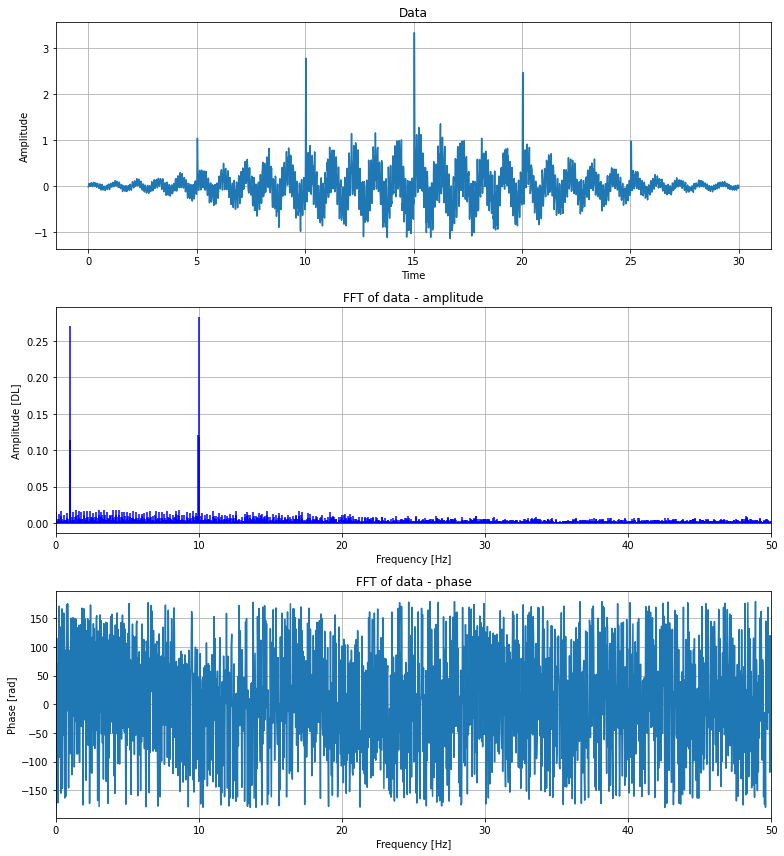

In [178]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [179]:
def calc_crest_factor(array):
    array = array[1]
    rms = np.sqrt(1 / len(array) * sum(array**2))
    return 10 * np.log10(max(array**2) / rms)


def calc_energy(array):
    array = array[1]
    return 1 / len(array) * sum(array**2)


def calc_kurtosis(array):
    array = array[1]
    return sc.kurtosis(array)


def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy":
            rec.sort(key=calc_energy, reverse=True)
        if sort_by == "kurtosis":
            rec.sort(key=lambda x: sc.kurtosis(x[1]), reverse=True)
        if sort_by == "crest":
            rec.sort(key=calc_crest_factor, reverse=True)

    elif sort == "coef":
        if sort_by == "energy":
            rec.sort(key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            rec.sort(key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            rec.sort(key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [180]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
coeffs = []
rec = []

for node in tr_ob.get_level(order="freq"):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs.append(tr_ob.nodes2data(rec_nodes))
    inverse = inv.inv_dwpt(coeffs[-1], wavelet)[:signal_length]
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    rec.append((node, inverse, fft))

plot the **`n_highest`** energy components (subbands).

sorted by: kurtosis of rec


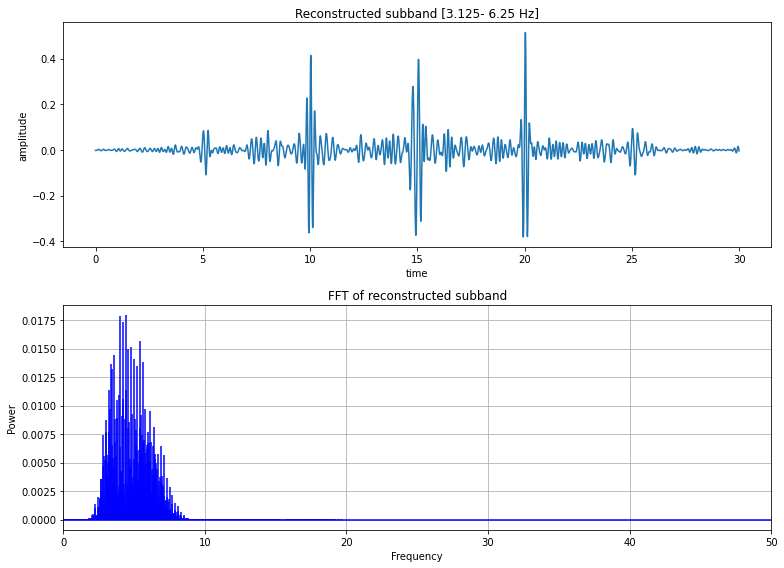

energy of recovered signal: 0.0034398758717183644
kurtosis of recovered signal: 23.358278560991952
crest factor of recovered signal: 6.537308113238619

energy of node coefficients: 0.047869698886025464
kurtosis of node coefficients: 17.460250694280965
crest factor of node coefficients: 9.96430552191432


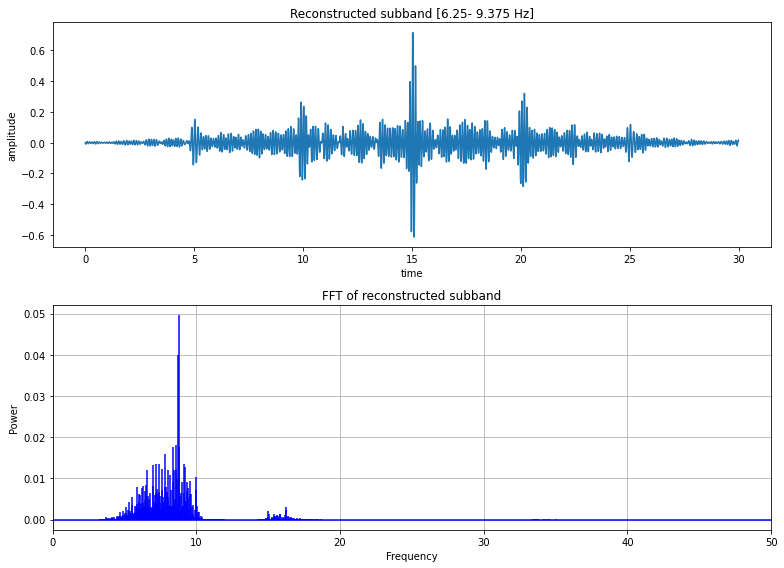

energy of recovered signal: 0.004979331265058409
kurtosis of recovered signal: 20.21889033777839
crest factor of recovered signal: 8.613697559474492

energy of node coefficients: 0.06946092350149753
kurtosis of node coefficients: 18.494208558239297
crest factor of node coefficients: 12.253801829524754


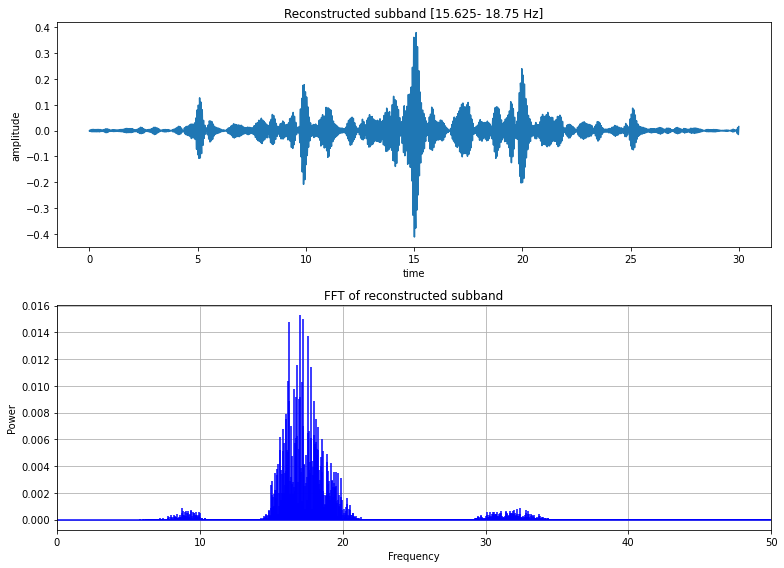

energy of recovered signal: 0.001900027636390481
kurtosis of recovered signal: 18.633933754342298
crest factor of recovered signal: 5.899880354889747

energy of node coefficients: 0.026473345161009812
kurtosis of node coefficients: 35.205901617983095
crest factor of node coefficients: 11.46029204497574


In [181]:
# sort reconstructed waves
sort_nodes(rec, sort, sort_by)
print(f"sorted by: {sort_by} of {sort}")
# plot highest energy subbands
partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
for i in range(len(rec)):
    node, rec_wave, fft = rec[i]
    if i in range(n_highest):  # highest energy, kurtosis, etc.
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        ax[0].set_title(f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]")
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {calc_energy(rec[i])}")
        print(f"kurtosis of recovered signal: {calc_kurtosis(rec[i])}")
        print(f"crest factor of recovered signal: {calc_crest_factor(rec[i])}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

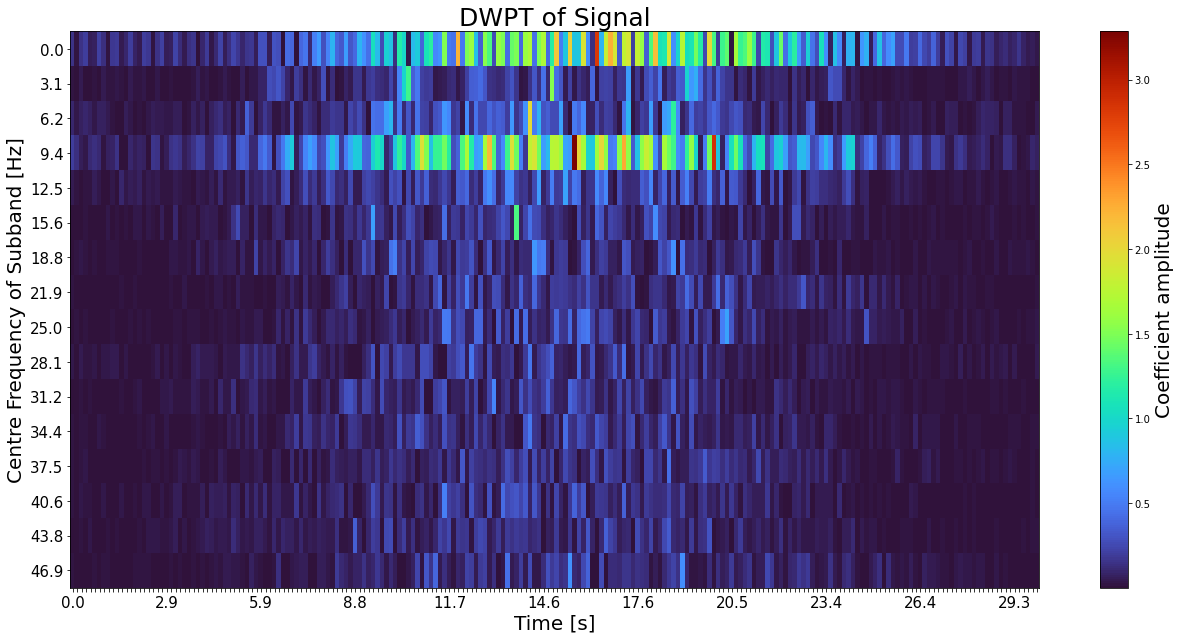

In [153]:
plot.heisenberg(tr_ob, max(t_plot), y_space=1)

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [185]:
from sklearn.cluster import KMeans

# training data
data_train = []
for i in rec:
    data_train.append((calc_energy(i),calc_crest_factor(i),calc_kurtosis(i)))

# training k-means algorithm
kmeans = KMeans(n_clusters=4)
kmeans.fit(data_train)

# get labels and clusters
labels = kmeans.labels_
centers = kmeans.cluster_centers_

print("Cluster Labels:", labels)
print("Cluster Centers:", centers)


Cluster Labels: [2 2 2 0 0 0 1 3 1 1 1 1 1 1 3 3]
Cluster Centers: [[ 1.09893854e-03  3.21214009e+00  1.15681180e+01]
 [ 5.75242887e-04 -2.51328930e+00  2.72067949e+00]
 [ 3.43974492e-03  7.01696201e+00  2.07370342e+01]
 [ 3.62167535e-02  3.79141114e+00  1.30954442e+00]]


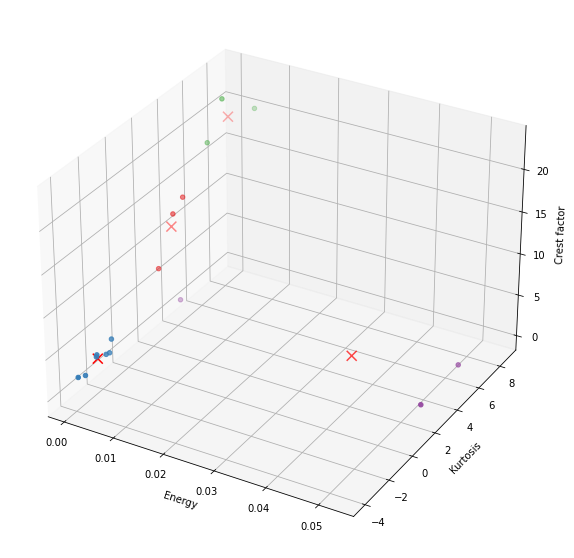

In [196]:
# 3d plot
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')
ax.scatter(
    [point[0] for point in data_train],
    [point[1] for point in data_train],
    [point[2] for point in data_train],
    c=[cmap(label) for label in labels]
)

# plot centres
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], c='red', marker='x', s=100)

ax.set_xlabel('Energy')
ax.set_ylabel('Kurtosis')
ax.set_zlabel('Crest factor')

# Show the 3D plot
plt.show()

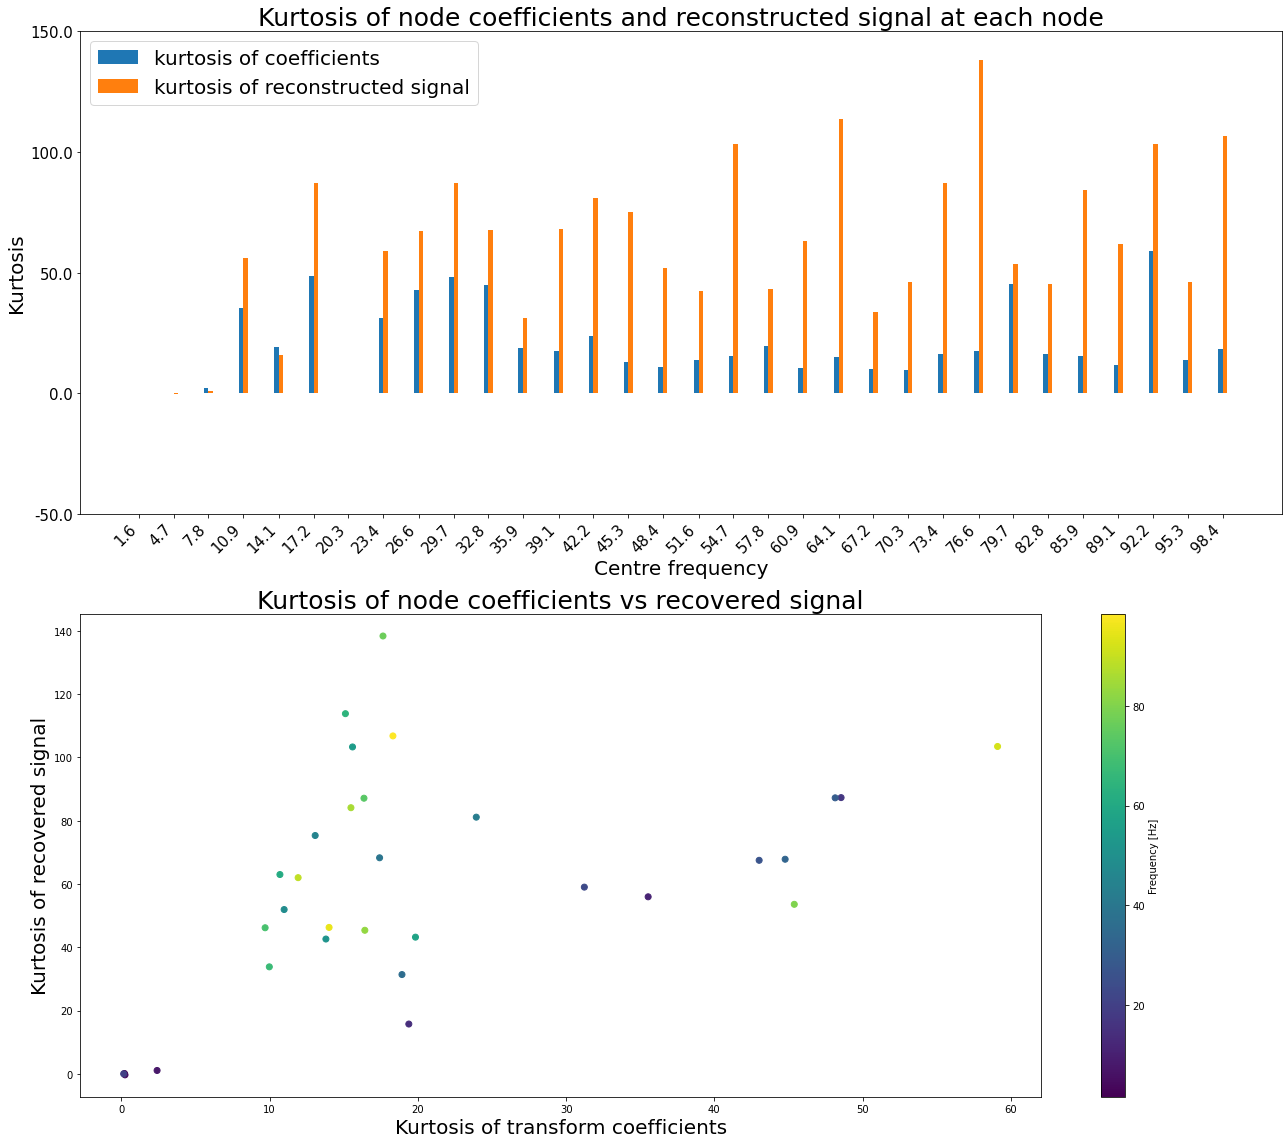

In [130]:
# gather data
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_ob.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]
coef_kurtosis = [node.kurtosis for node, _, _ in rec]
kurtosis = [calc_kurtosis(i) for i in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_kurtosis, width, align="center", label="kurtosis of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    kurtosis,
    width,
    align="center",
    label="kurtosis of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Kurtosis of node coefficients and reconstructed signal at each node", fontsize=25
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Kurtosis", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax[1].set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax[1].set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

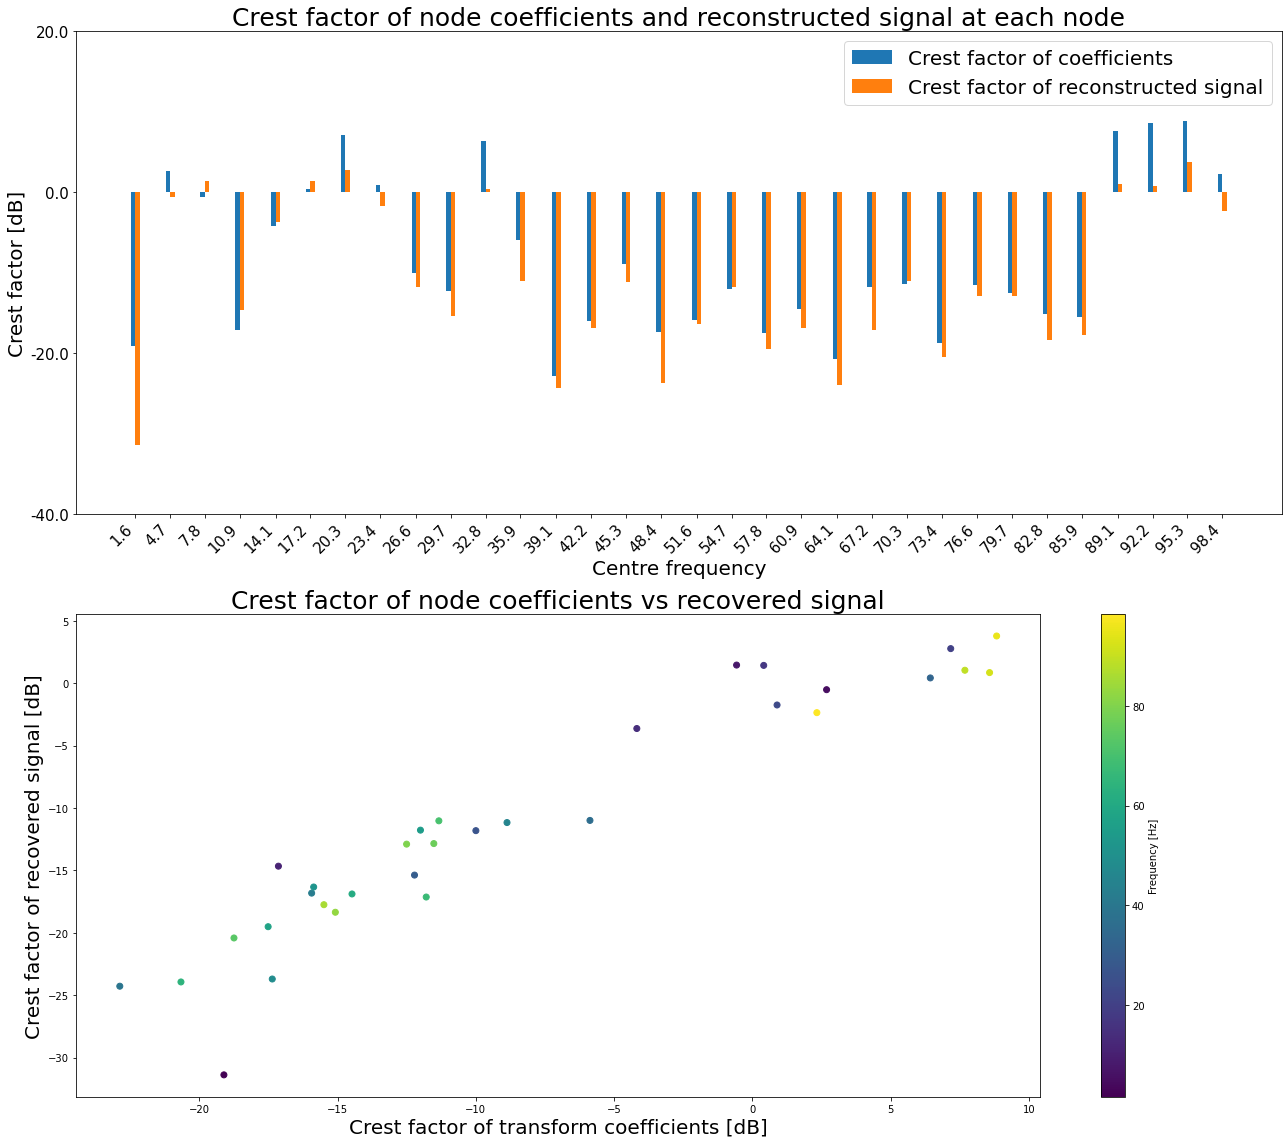

In [121]:
# gather data
coef_crest = [node.crest_factor for node, _, _ in rec]
crest = [calc_crest_factor(i) for i in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_crest, width, align="center", label="Crest factor of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    crest,
    width,
    align="center",
    label="Crest factor of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Crest factor of node coefficients and reconstructed signal at each node",
    fontsize=25,
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Crest factor [dB]", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_crest, crest, c=cent_freqs)
ax[1].set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax[1].set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

### plot of reconstruction

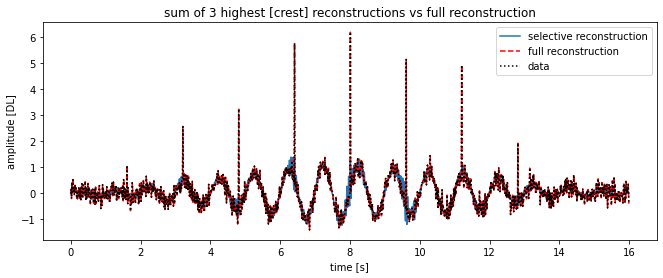

In [11]:
# plot sum of highest energy subbands
plt.figure(figsize=(11, 4))
plt.plot(t_plot, partial_rec)
plt.xlabel("time [s]")
plt.ylabel("amplitude [DL]")
plt.title(
    f"sum of {n_highest} highest [{sort_by}] reconstructions vs full reconstruction"
)

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob.nodes2data(tr_ob.get_level()), wavelet)
plt.plot(t_plot, full_rec[:signal_length], "--r")
plt.plot(t_plot, data, ":k")
plt.legend(["selective reconstruction", "full reconstruction", "data"], loc="best")
plt.show()

### testing frequency sorting algorithm

In [8]:
my_frequencies = [node.path for node in tr_ob.get_level(order="freq")]
pywt_nodes = pywt._wavelet_packets.get_graycode_order(levels)
print("my nodes ordered by frequency:", my_frequencies)
print("pywt order:                   ", pywt_nodes)
print(my_frequencies == pywt_nodes)

my nodes ordered by frequency: ['aaaaaaaa', 'aaaaaaad', 'aaaaaadd', 'aaaaaada', 'aaaaadda', 'aaaaaddd', 'aaaaadad', 'aaaaadaa', 'aaaaddaa', 'aaaaddad', 'aaaadddd', 'aaaaddda', 'aaaadada', 'aaaadadd', 'aaaadaad', 'aaaadaaa', 'aaaddaaa', 'aaaddaad', 'aaaddadd', 'aaaddada', 'aaadddda', 'aaaddddd', 'aaadddad', 'aaadddaa', 'aaadadaa', 'aaadadad', 'aaadaddd', 'aaadadda', 'aaadaada', 'aaadaadd', 'aaadaaad', 'aaadaaaa', 'aaddaaaa', 'aaddaaad', 'aaddaadd', 'aaddaada', 'aaddadda', 'aaddaddd', 'aaddadad', 'aaddadaa', 'aaddddaa', 'aaddddad', 'aadddddd', 'aaddddda', 'aadddada', 'aadddadd', 'aadddaad', 'aadddaaa', 'aadadaaa', 'aadadaad', 'aadadadd', 'aadadada', 'aadaddda', 'aadadddd', 'aadaddad', 'aadaddaa', 'aadaadaa', 'aadaadad', 'aadaaddd', 'aadaadda', 'aadaaada', 'aadaaadd', 'aadaaaad', 'aadaaaaa', 'addaaaaa', 'addaaaad', 'addaaadd', 'addaaada', 'addaadda', 'addaaddd', 'addaadad', 'addaadaa', 'addaddaa', 'addaddad', 'addadddd', 'addaddda', 'addadada', 'addadadd', 'addadaad', 'addadaaa', 'addddaa